In [ ]:
!pip install --upgrade pip  # ensures that pip is current
!pip install "unbabel-comet>=2.0.0"
!pip install datasets==2.21.0 # https://github.com/huggingface/datasets/issues/7693

In [ ]:
!pip install iterative-stratification

In [ ]:
import os
import requests
from zipfile import ZipFile
from tqdm import tqdm
import numpy as np
from datasets import load_dataset, DatasetDict
from transformers import pipeline, AutoModelForSeq2SeqLM, AutoTokenizer, Trainer, TrainingArguments
from sentence_transformers import SentenceTransformer
from comet import download_model, load_from_checkpoint
from transformers import logging as hf_logging
import torch
from collections import defaultdict
import random
import aiohttp
from huggingface_hub import notebook_login

import matplotlib.pyplot as plt
from pycocotools.coco import COCO

import logging
import time

from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit
from itertools import chain
from collections import Counter
import functools

In [ ]:
#Set random seed for reproducibility
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

In [ ]:
hf_logging.set_verbosity_error()

In [ ]:
def setup_notebook_logger():
    logger = logging.getLogger()
    logger.setLevel(logging.INFO)

    if logger.hasHandlers():
        logger.handlers.clear()

    handler = logging.StreamHandler()
    handler.setLevel(logging.INFO)

    formatter = logging.Formatter("[%(asctime)s] [%(levelname)s] %(message)s",
                                  datefmt="%H:%M:%S")
    handler.setFormatter(formatter)

    logger.addHandler(handler)
    return logger

logger = setup_notebook_logger()

# Test
logger.info("Notebook logger is working ✅")

[10:21:53] [INFO] Notebook logger is working ✅


In [ ]:
def log_time(func):
    @functools.wraps(func)
    def wrapper(*args, **kwargs):
        start = time.time()
        result = func(*args, **kwargs)
        end = time.time()
        logger.info(f"{func.__name__}() took {end - start:.2f} seconds")
        return result
    return wrapper

# Download datasets

In [ ]:
def load_coco_dataset():
    dataset = load_dataset(
        "shunk031/MSCOCO",
        year=2017,
        coco_task="captions",
        cache_dir="/content/hf_cache"
    )
    return dataset

In [ ]:
dataset = load_coco_dataset()

In [ ]:
instance_dataset = load_dataset(
    "shunk031/MSCOCO",
    year=2017,
    coco_task="instances",
    cache_dir="/content/hf_cache"
)

Generating train split: 0 examples [00:00, ? examples/s]

Load images:   0%|          | 0/118287 [00:00<?, ?it/s]

Load categories:   0%|          | 0/80 [00:00<?, ?it/s]

Load instances data:   0%|          | 0/860001 [00:00<?, ?it/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Load images:   0%|          | 0/5000 [00:00<?, ?it/s]

Load categories:   0%|          | 0/80 [00:00<?, ?it/s]

Load instances data:   0%|          | 0/36781 [00:00<?, ?it/s]

In [ ]:
@log_time
def create_balanced_subset(captions_dataset, instance_dataset, split, fraction=0.5, num_cats=120):
    logger.info(f"📂 Creating subset for split='{split}', fraction={fraction}, num_cats={num_cats}")

    captions_split, instance_split = captions_dataset[split], instance_dataset[split]
    logger.info(f"Loaded dataset splits: captions={len(captions_split)}, instances={len(instance_split)}")

    # Build mapping: image -> categories
    img2cat = defaultdict(list)
    img_id_to_idx = {}
    for idx, (image_id, annotations) in enumerate(zip(instance_split['image_id'], instance_split['annotations'])):
        img2cat[image_id].extend(annotations['category_id'])
        img_id_to_idx[image_id] = idx
    logger.info(f"Built img2cat mapping for {len(img2cat)} images")

    # Build mapping: image -> captions
    img2captions = defaultdict(list)
    for image_id, annotations in zip(captions_split['image_id'], captions_split['annotations']):
        img2captions[image_id].extend(annotations['caption'])
    logger.info(f"Built img2captions mapping for {len(img2captions)} images")

    # Keep only images that have both captions + categories
    image_ids = [img_id for img_id in img2captions if img_id in img2cat]
    logger.info(f"Eligible images after filtering: {len(image_ids)}")

    # Build one-hot label matrix
    rows, cols = [], []
    for i, img_id in enumerate(image_ids):
        rows.extend([i] * len(img2cat[img_id]))
        cols.extend(img2cat[img_id])
    Y = np.zeros((len(image_ids), num_cats), dtype=np.int8)
    Y[rows, cols] = 1
    logger.info(f"Built one-hot label matrix: shape={Y.shape}, nnz={len(rows)}")

    # Dummy X (not used)
    X = np.zeros((len(image_ids), 1), dtype=np.int8)

    # Stratified split
    msss = MultilabelStratifiedShuffleSplit(n_splits=1, test_size=fraction, random_state=42)
    _, subset_idx = next(msss.split(X, Y))
    logger.info(f"Selected subset size={len(subset_idx)} ({fraction*100:.1f}% of total)")

    # Map back to ids + indices
    subset_image_ids = [image_ids[i] for i in subset_idx]
    subset_idx = [img_id_to_idx[image_id] for image_id in subset_image_ids]

    logger.info("Subset creation complete.")
    return subset_image_ids, subset_idx

In [ ]:
def plot_category_distribution(image_ids, annotations, category_names=None, title="Category Distribution"):
    """
    Faster version: directly counts category frequencies without building one huge list.
    """
    cat_counts = Counter()

    # Directly count per image without building all_cats list
    for img_id in image_ids:
        for c in annotations.get(img_id, []):
            cat_counts[c] += 1

    # Sort for consistency
    cat_ids = sorted(cat_counts.keys())
    counts = [cat_counts[c] for c in cat_ids]

    # Use category names if provided
    if category_names:
        labels = [category_names.get(c, str(c)) for c in cat_ids]
    else:
        labels = [str(c) for c in cat_ids]

    # Plot
    plt.figure(figsize=(12, 6))
    plt.bar(labels, counts)
    plt.xticks(rotation=90)
    plt.xlabel("Category")
    plt.ylabel("Frequency")
    plt.title(title)
    plt.tight_layout()
    plt.show()

In [ ]:
dataset['train']

Dataset({
    features: ['image_id', 'image', 'file_name', 'coco_url', 'height', 'width', 'date_captured', 'flickr_url', 'license_id', 'license', 'annotations'],
    num_rows: 118287
})

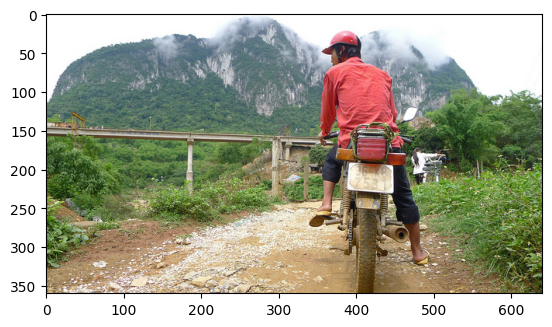

In [ ]:
plt.imshow(dataset['train'][0]['image'])

In [ ]:
tr_image_ids, tr_indices = create_balanced_subset(dataset, instance_dataset, 'train')

[12:06:45] [INFO] 📂 Creating subset for split='train', fraction=0.5, num_cats=120
[12:06:45] [INFO] Loaded dataset splits: captions=118287, instances=117266
[12:09:05] [INFO] Built img2cat mapping for 117266 images
[12:09:10] [INFO] Built img2captions mapping for 118287 images
[12:09:10] [INFO] Eligible images after filtering: 117266
[12:09:10] [INFO] Built one-hot label matrix: shape=(117266, 120), nnz=860001
[12:09:13] [INFO] Selected subset size=58549 (50.0% of total)
[12:09:13] [INFO] Subset creation complete.
[12:09:13] [INFO] create_balanced_subset() took 147.48 seconds


In [ ]:
def extract_subset(dataset, image_ids):
  image_id_set = set(image_ids)
  selected = dataset.filter(lambda x: x["image_id"] in image_id_set)
  return selected

In [ ]:
train_subset_captions = extract_subset(dataset['train'], tr_image_ids)

Filter:   0%|          | 0/118287 [00:00<?, ? examples/s]

In [ ]:
train_subset_instances = extract_subset(instance_dataset['train'], tr_image_ids)

Filter:   0%|          | 0/117266 [00:00<?, ? examples/s]

In [ ]:
train_subset_captions

Dataset({
    features: ['image_id', 'image', 'file_name', 'coco_url', 'height', 'width', 'date_captured', 'flickr_url', 'license_id', 'license', 'annotations'],
    num_rows: 58549
})

In [ ]:
train_subset_instances

Dataset({
    features: ['image_id', 'image', 'file_name', 'coco_url', 'height', 'width', 'date_captured', 'flickr_url', 'license_id', 'license', 'annotations'],
    num_rows: 58549
})

[12:52:41] [INFO] Built annotations mapping
[12:52:41] [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
[12:52:41] [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


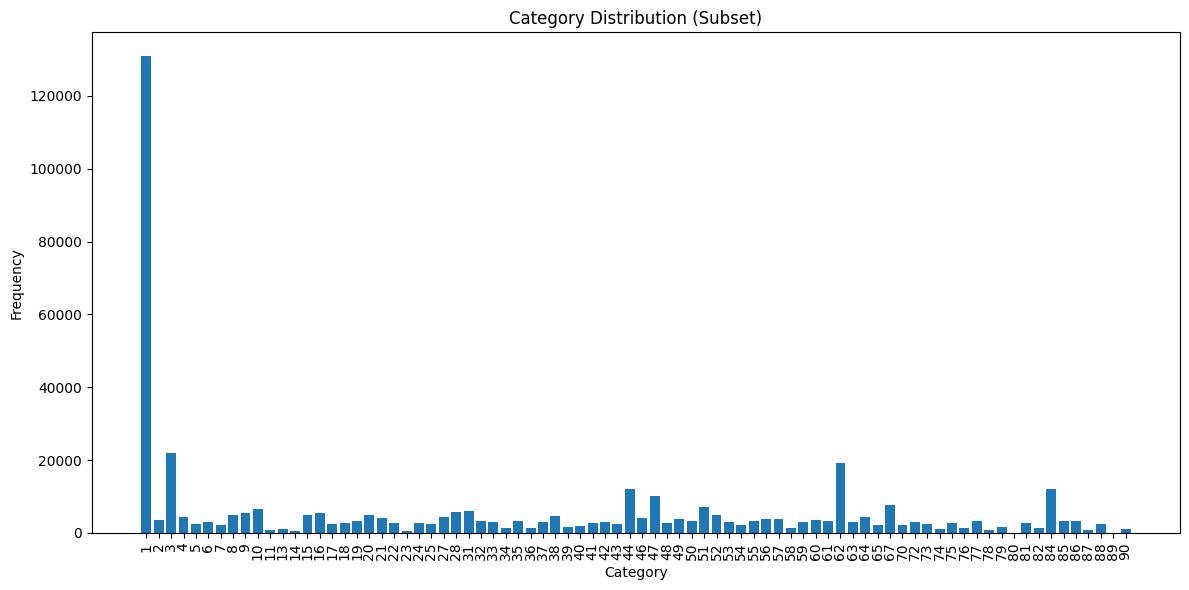

In [ ]:
annts = {}
for row in train_subset_instances:
    annts[row['image_id']]= row['annotations']['category_id']
logger.info("Built annotations mapping")
plot_category_distribution(tr_image_ids, annts, title="Category Distribution (Subset)")

[13:05:42] [INFO] Built annotations mapping
[13:14:09] [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
[13:14:09] [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


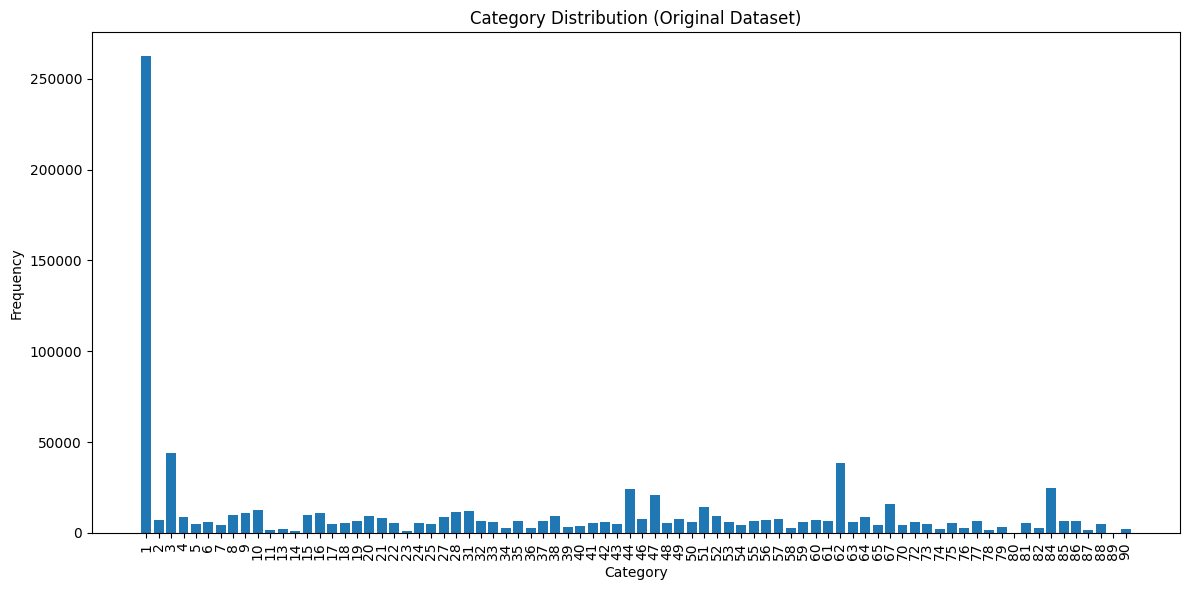

In [ ]:
annts = {}
for row in instance_dataset['train']:
  annts[row['image_id']]= row['annotations']['category_id']
logger.info("Built annotations mapping")
image_ids = [smp['image_id'] for smp in dataset['train']]
plot_category_distribution(image_ids, annts, title="Category Distribution (Original Dataset)")

In [ ]:
coco_captions_subset = DatasetDict({
    'train': train_subset_captions,
    'validation': dataset['validation']
})

In [ ]:
coco_instances_subset = DatasetDict({
    'train': train_subset_instances,
    'validation': instance_dataset['validation']
})

In [ ]:
notebook_login()

In [ ]:
COCO_SUBSET_CAPTIONS_ID = "umairhassan02/coco-captions-subset-59k"
coco_captions_subset.push_to_hub(COCO_SUBSET_CAPTIONS_ID, max_shard_size="500MB")

Uploading the dataset shards:   0%|          | 0/20 [00:00<?, ?it/s]

Map:   0%|          | 0/2928 [00:00<?, ? examples/s]

Creating parquet from Arrow format:   0%|          | 0/30 [00:00<?, ?ba/s]

Uploading files as a binary IO buffer is not supported by Xet Storage. Falling back to HTTP upload.
[14:05:21] [WARNING] Uploading files as a binary IO buffer is not supported by Xet Storage. Falling back to HTTP upload.


Map:   0%|          | 0/2928 [00:00<?, ? examples/s]

...

Creating parquet from Arrow format:   0%|          | 0/25 [00:00<?, ?ba/s]

Uploading files as a binary IO buffer is not supported by Xet Storage. Falling back to HTTP upload.
[14:09:23] [WARNING] Uploading files as a binary IO buffer is not supported by Xet Storage. Falling back to HTTP upload.


README.md: 0.00B [00:00, ?B/s]

No files have been modified since last commit. Skipping to prevent empty commit.
[14:09:24] [WARNING] No files have been modified since last commit. Skipping to prevent empty commit.


CommitInfo(commit_url='https://huggingface.co/datasets/umairhassan02/coco-captions-subset-59k/commit/d523357c0c01ceed89616409cc63f287432d248d', commit_message='Upload dataset', commit_description='', oid='d523357c0c01ceed89616409cc63f287432d248d', pr_url=None, repo_url=RepoUrl('https://huggingface.co/datasets/umairhassan02/coco-captions-subset-59k', endpoint='https://huggingface.co', repo_type='dataset', repo_id='umairhassan02/coco-captions-subset-59k'), pr_revision=None, pr_num=None)

In [ ]:
coco_instances_subset['validation'].features

{'image_id': Value(dtype='int64', id=None),
 'image': Image(mode=None, decode=True, id=None),
 'file_name': Value(dtype='string', id=None),
 'coco_url': Value(dtype='string', id=None),
 'height': Value(dtype='int32', id=None),
 'width': Value(dtype='int32', id=None),
 'date_captured': Value(dtype='string', id=None),
 'flickr_url': Value(dtype='string', id=None),
 'license_id': Value(dtype='int32', id=None),
 'license': {'url': Value(dtype='string', id=None),
  'license_id': Value(dtype='int8', id=None),
  'name': Value(dtype='string', id=None)},
 'annotations': Sequence(feature={'annotation_id': Value(dtype='int64', id=None), 'image_id': Value(dtype='int64', id=None), 'segmentation': {'counts': Sequence(feature=Value(dtype='int64', id=None), length=-1, id=None), 'size': Sequence(feature=Value(dtype='int32', id=None), length=-1, id=None)}, 'area': Value(dtype='float32', id=None), 'iscrowd': Value(dtype='bool', id=None), 'bbox': Sequence(feature=Value(dtype='float32', id=None), length=4,

In [ ]:
from datasets import Dataset, DatasetDict, Features, Value, Sequence, Image, ClassLabel

In [ ]:
features = Features({
    'image_id': Value(dtype='int64'),
    'image': Image(decode=True),
    'file_name': Value(dtype='string'),
    'coco_url': Value(dtype='string'),
    'height': Value(dtype='int32'),
    'width': Value(dtype='int32'),
    'date_captured': Value(dtype='string'),
    'flickr_url': Value(dtype='string'),
    'license_id': Value(dtype='int32'),
    'license': {
        'url': Value(dtype='string'),
        'license_id': Value(dtype='int8'),
        'name': Value(dtype='string')
    },
    'annotations': Sequence({
        'annotation_id': Value(dtype='int64'),
        'image_id': Value(dtype='int64'),
        'segmentation': {
            'counts': Sequence(Value(dtype='int64')),
            'size': Sequence(Value(dtype='int32'))
        },
        'area': Value(dtype='float32'),
        'iscrowd': Value(dtype='bool'),
        'bbox': Sequence(Value(dtype='float32'), length=4),
        'category_id': Value(dtype='int32'),
        'category': {
            'category_id': Value(dtype='int32'),
            'name': ClassLabel(names=[
                'person', 'bicycle', 'car', 'motorcycle', 'airplane', 'bus', 'train', 'truck', 'boat',
                'traffic light', 'fire hydrant', 'stop sign', 'parking meter', 'bench', 'bird', 'cat',
                'dog', 'horse', 'sheep', 'cow', 'elephant', 'bear', 'zebra', 'giraffe', 'backpack',
                'umbrella', 'handbag', 'tie', 'suitcase', 'frisbee', 'skis', 'snowboard', 'sports ball',
                'kite', 'baseball bat', 'baseball glove', 'skateboard', 'surfboard', 'tennis racket',
                'bottle', 'wine glass', 'cup', 'fork', 'knife', 'spoon', 'bowl', 'banana', 'apple',
                'sandwich', 'orange', 'broccoli', 'carrot', 'hot dog', 'pizza', 'donut', 'cake',
                'chair', 'couch', 'potted plant', 'bed', 'dining table', 'toilet', 'tv', 'laptop',
                'mouse', 'remote', 'keyboard', 'cell phone', 'microwave', 'oven', 'toaster', 'sink',
                'refrigerator', 'book', 'clock', 'vase', 'scissors', 'teddy bear', 'hair drier', 'toothbrush'
            ]),
            'supercategory': ClassLabel(names=[
                'person', 'vehicle', 'outdoor', 'animal', 'accessory', 'sports', 'kitchen', 'food',
                'furniture', 'electronic', 'appliance', 'indoor'
            ])
        }
    })
})

In [ ]:
COCO_SUBSET_INSTANCES_ID = "umairhassan02/coco-instances-subset-59k"
coco_instances_subset.push_to_hub(COCO_SUBSET_INSTANCES_ID,  max_shard_size="500MB")

Uploading the dataset shards:   0%|          | 0/22 [00:00<?, ?it/s]

Map:   0%|          | 0/2662 [00:00<?, ? examples/s]

Creating parquet from Arrow format:   0%|          | 0/27 [00:00<?, ?ba/s]

Uploading files as a binary IO buffer is not supported by Xet Storage. Falling back to HTTP upload.
[14:41:26] [WARNING] Uploading files as a binary IO buffer is not supported by Xet Storage. Falling back to HTTP upload.


Map:   0%|          | 0/2662 [00:00<?, ? examples/s]

...

Uploading files as a binary IO buffer is not supported by Xet Storage. Falling back to HTTP upload.
[14:46:29] [WARNING] Uploading files as a binary IO buffer is not supported by Xet Storage. Falling back to HTTP upload.


Map:   0%|          | 0/2476 [00:00<?, ? examples/s]

Creating parquet from Arrow format:   0%|          | 0/25 [00:00<?, ?ba/s]

Uploading files as a binary IO buffer is not supported by Xet Storage. Falling back to HTTP upload.
[14:46:41] [WARNING] Uploading files as a binary IO buffer is not supported by Xet Storage. Falling back to HTTP upload.


CommitInfo(commit_url='https://huggingface.co/datasets/umairhassan02/coco-instances-subset-59k/commit/76a778ac04c8e1c8b1a1a0f5ee4357ea28bcd5be', commit_message='Upload dataset', commit_description='', oid='76a778ac04c8e1c8b1a1a0f5ee4357ea28bcd5be', pr_url=None, repo_url=RepoUrl('https://huggingface.co/datasets/umairhassan02/coco-instances-subset-59k', endpoint='https://huggingface.co', repo_type='dataset', repo_id='umairhassan02/coco-instances-subset-59k'), pr_revision=None, pr_num=None)